## 1. IMPORTING LIBRARIES

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load and inspect the data


### 2.1  Loading and Summarizing the Dataset

In [19]:
#
df = pd.read_csv("data/Sleep_Efficiency.csv")

print("Dataset shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

display(df.head())

print("Dataset information:")
df.info()

print("Statistical summary:")
display(df.describe())

print("Duplicate rows:", df.duplicated().sum())

print("Missing values:")
display(df.isnull().sum())

Dataset shape: (452, 15)
Number of Rows: 452
Number of Columns: 15


,ID,Age,Gender,Bedtime,Wakeup time,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
0,1,65,Female,2021-03-06 01:00:00,2021-03-06 07:00:00,6.0,0.88,18,70,12,0.0,0.0,0.0,Yes,3.0
1,2,69,Male,2021-12-05 02:00:00,2021-12-05 09:00:00,7.0,0.66,19,28,53,3.0,0.0,3.0,Yes,3.0
2,3,40,Female,2021-05-25 21:30:00,2021-05-25 05:30:00,8.0,0.89,20,70,10,1.0,0.0,0.0,No,3.0
3,4,40,Female,2021-11-03 02:30:00,2021-11-03 08:30:00,6.0,0.51,23,25,52,3.0,50.0,5.0,Yes,1.0
4,5,57,Male,2021-03-13 01:00:00,2021-03-13 09:00:00,8.0,0.76,27,55,18,3.0,0.0,3.0,No,3.0


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      452 non-null    int64  
 1   Age                     452 non-null    int64  
 2   Gender                  452 non-null    str    
 3   Bedtime                 452 non-null    str    
 4   Wakeup time             452 non-null    str    
 5   Sleep duration          452 non-null    float64
 6   Sleep efficiency        452 non-null    float64
 7   REM sleep percentage    452 non-null    int64  
 8   Deep sleep percentage   452 non-null    int64  
 9   Light sleep percentage  452 non-null    int64  
 10  Awakenings              432 non-null    float64
 11  Caffeine consumption    427 non-null    float64
 12  Alcohol consumption     438 non-null    float64
 13  Smoking status          452 non-null    str    
 14  Exercise frequency      446 non-

,ID,Age,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Exercise frequency
count,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,432.000000,427.000000,438.000000,446.000000
mean,226.500000,40.285398,7.465708,0.788916,22.615044,52.823009,24.561947,1.641204,23.653396,1.173516,1.791480
std,130.625419,13.172250,0.866625,0.135237,3.525963,15.654235,15.313665,1.356762,30.202785,1.621377,1.428134
min,1.000000,9.000000,5.000000,0.500000,15.000000,18.000000,7.000000,0.000000,0.000000,0.000000,0.000000
25%,113.750000,29.000000,7.000000,0.697500,20.000000,48.250000,15.000000,1.000000,0.000000,0.000000,0.000000
50%,226.500000,40.000000,7.500000,0.820000,22.000000,58.000000,18.000000,1.000000,25.000000,0.000000,2.000000
75%,339.250000,52.000000,8.000000,0.900000,25.000000,63.000000,32.500000,3.000000,50.000000,2.000000,3.000000
max,452.000000,69.000000,10.000000,0.990000,30.000000,75.000000,63.000000,4.000000,200.000000,5.000000,5.000000


Duplicate rows: 0
Missing values:


ID                         0
Age                        0
Gender                     0
Bedtime                    0
Wakeup time                0
Sleep duration             0
Sleep efficiency           0
REM sleep percentage       0
Deep sleep percentage      0
Light sleep percentage     0
Awakenings                20
Caffeine consumption      25
Alcohol consumption       14
Smoking status             0
Exercise frequency         6
dtype: int64

### 2.2 Sleep Efficiency Distribution

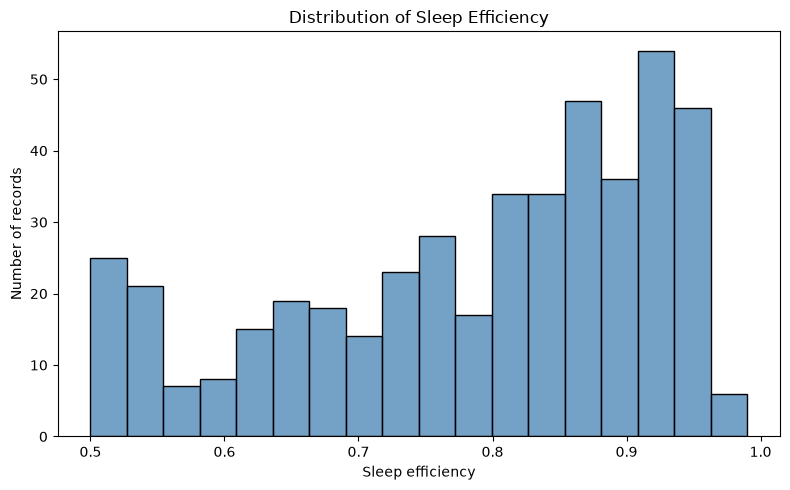

In [20]:
target_column = "Sleep efficiency"


plt.figure(figsize=(8, 5))
sns.histplot(df[target_column], bins=18,  color="steelblue")

plt.title("Distribution of Sleep Efficiency")
plt.xlabel("Sleep efficiency")
plt.ylabel("Number of records")

plt.tight_layout()
plt.show()

### 2.3 Numeric Feature Correlations with Sleep Efficiency

In [21]:
numeric_eda = df.select_dtypes(include=np.number).drop(columns=["ID"], errors="ignore")
efficiency_correlations = (
    numeric_eda.corr()[target_column]
    .drop(target_column)
    .sort_values()
)
print("Pearson correlations with sleep efficiency:")
display(efficiency_correlations.to_frame(name="Correlation").round(3))

Pearson correlations with sleep efficiency:


,Correlation
Light sleep percentage,-0.819
Awakenings,-0.565
Alcohol consumption,-0.390
Sleep duration,-0.027
REM sleep percentage,0.062
Caffeine consumption,0.065
Age,0.098
Exercise frequency,0.260
Deep sleep percentage,0.787


## 3. Feature handeling and Feature Selection

### 3.1 Feature handeling 


In [22]:
# Convert clock times to decimal

bedtime = pd.to_datetime(df["Bedtime"], errors="coerce")
wakeup = pd.to_datetime(df["Wakeup time"], errors="coerce")

bedtime_hours = (bedtime.dt.hour+ bedtime.dt.minute / 60+ bedtime.dt.second / 3600)
wakeup_hours = (wakeup.dt.hour+ wakeup.dt.minute / 60+ wakeup.dt.second / 3600)

# change each clock time (for near to midnight stay close) and for 
df["Bedtime sin"] = np.sin(2 * np.pi * bedtime_hours / 24)
df["Bedtime cos"] = np.cos(2 * np.pi * bedtime_hours / 24)
df["Wakeup sin"] = np.sin(2 * np.pi * wakeup_hours / 24)
df["Wakeup cos"] = np.cos(2 * np.pi * wakeup_hours / 24)



### 3.2 Feature selection

In [23]:
#selecting the input and output parameters

target_column = "Sleep efficiency"

columns_to_exclude = ["ID","Bedtime","Wakeup time",target_column] #excluded bedtime and wakeup time as we are using their sin and cos. 

X = df.drop(columns=columns_to_exclude)
y = df[target_column]

print("Feature columns:")
print(X.columns.tolist())
print("\nTarget column:", y.name)
print("\nFeature data shape:", X.shape)

Feature columns:
['Age', 'Gender', 'Sleep duration', 'REM sleep percentage', 'Deep sleep percentage', 'Light sleep percentage', 'Awakenings', 'Caffeine consumption', 'Alcohol consumption', 'Smoking status', 'Exercise frequency', 'Bedtime sin', 'Bedtime cos', 'Wakeup sin', 'Wakeup cos']

Target column: Sleep efficiency

Feature data shape: (452, 15)


## 4. Splitting data into Training and Test Sets

20% data for testing , 80% for training ,and fixed random state for reproducing.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 361
Test rows: 91


## 5. Preprocessing Features

Imputing numeric missing values with the  median and scaling numeric predictors. Filling missing categorical values with the most frequent category and onehot encode them.

In [25]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print("Data preprocessing complete")

Data preprocessing complete


## 6. Training the Multiple Linear Regression Model

Fitting multiple linear regression using the training data and generating test predictions.

In [26]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression()),
])
model.fit(X_train, y_train)

test_predictions = model.predict(X_test)

print("Model fitting and predictions complete")

Model fitting and predictions complete


## 7. Evaluation

Calculating and displaying R², mean absolute error (MAE), and root mean squared error (RMSE) for  test predictions.

In [31]:
metrics = pd.DataFrame([
    
    {
        "Dataset": "Test (y_yest)",
        "Rows": len(y_test),
        "R2": r2_score(y_test, test_predictions),
        "MAE": mean_absolute_error(y_test, test_predictions),
        "MSE":mean_squared_error(y_test, test_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
    }
])

print("Model results:")
display(metrics.round(4))

test_results = pd.DataFrame({
    "Actual efficiency": y_test.to_numpy(),
    "Predicted efficiency": test_predictions,
    "Residual": y_test.to_numpy() - test_predictions,
})
print("First five test predictions:")
display(test_results.head())

Model results:


,Dataset,Rows,R2,MAE,MSE,RMSE
0,Test (y_yest),91,0.7919,0.0507,0.0039,0.0622


First five test predictions:


,Actual efficiency,Predicted efficiency,Residual
0,0.60,0.536224,0.063776
1,0.63,0.569875,0.060125
2,0.90,0.867798,0.032202
3,0.56,0.666979,-0.106979
4,0.70,0.786545,-0.086545


## 8. Plots

### 8.1 Actual vs predicted sleep efficiency plot

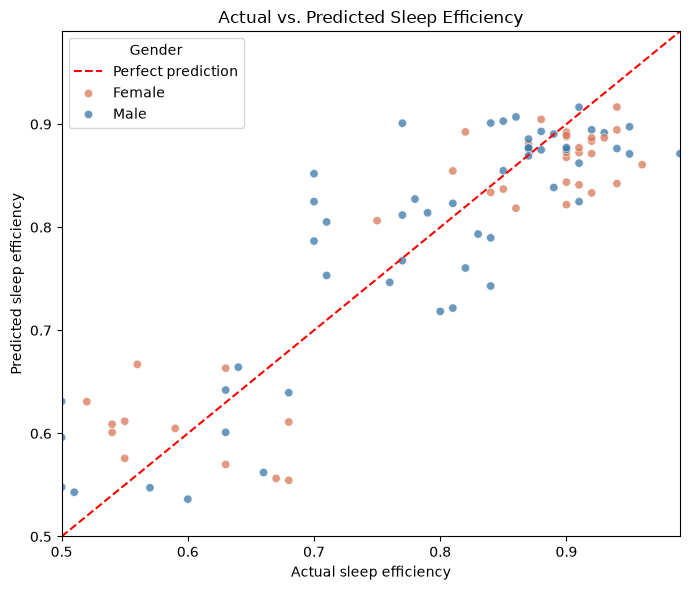

In [28]:
gender_palette = {"Female": "#d97757", "Male": "#3977a8"}

actual_values = y_test.to_numpy()
predicted_values = np.asarray(test_predictions)
gender_values = X_test["Gender"].astype(str).to_numpy()

low = min(actual_values.min(), predicted_values.min())
high = max(actual_values.max(), predicted_values.max())

plt.figure(figsize=(7, 6))
plt.plot([low, high], [low, high], linestyle="--", color="red", label="Perfect prediction")

sns.scatterplot(
    x=actual_values,
    y=predicted_values,
    hue=gender_values,
    hue_order=["Female", "Male"],
    palette=gender_palette,
    alpha=0.75,
)

plt.title("Actual vs. Predicted Sleep Efficiency")
plt.xlabel("Actual sleep efficiency")
plt.ylabel("Predicted sleep efficiency")
plt.xlim(low, high)
plt.ylim(low, high)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

### 8.2 Regression Coefficient Analysis

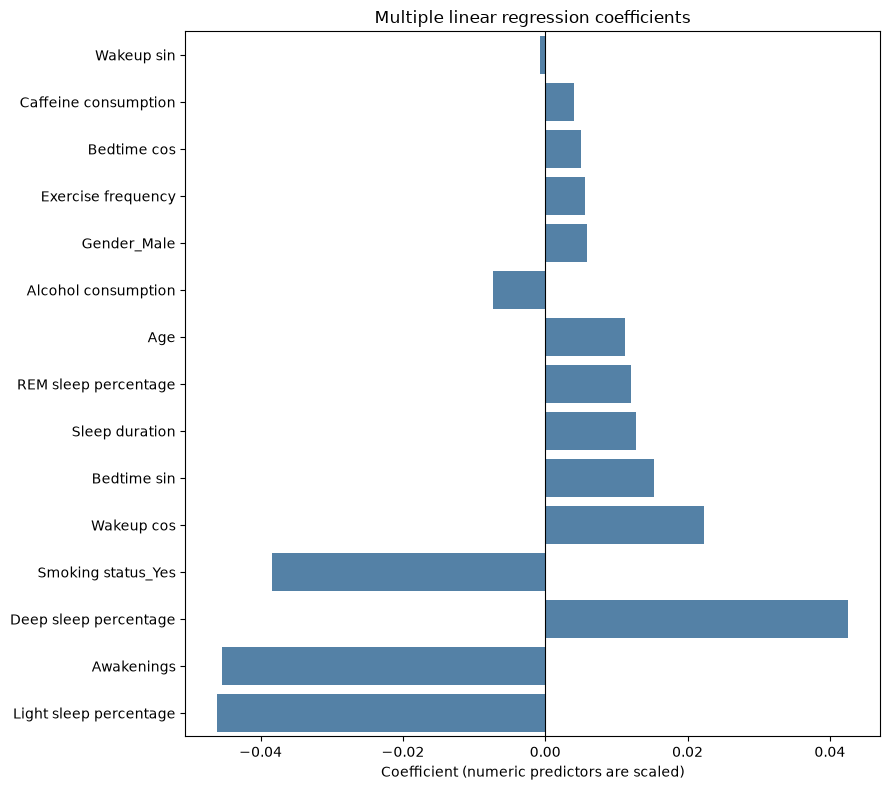

In [29]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
# Remove ColumnTransformer prefixes (for example, "numeric__") from plot labels for more better look.
clean_feature_names = [name.split("__", 1)[-1] for name in feature_names]
coefficients = model.named_steps["regression"].coef_
coefficient_table = pd.DataFrame({
    "Feature": clean_feature_names,
    "Coefficient": coefficients,
}).sort_values("Coefficient", key=lambda values: values.abs())

plt.figure(figsize=(9, 8))
sns.barplot(data=coefficient_table, x="Coefficient", y="Feature", color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Multiple linear regression coefficients")
plt.xlabel("Coefficient (numeric predictors are scaled)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 9. Conclusion

The multiple linear regression model achieved a test R-squared of approximately **0.792**, with a test MAE of **0.051**,MSE of **0.0039** and RMSE of **0.062**. On this test split, the model explains about 79% of the variation in sleep-efficiency values.However, the dataset contains only 452 rows and the evaluation uses one train/test split, so performance may differ on new data. These results show predictive associations as per multiple linear regression and do not guarantee that any predictor causes changes in sleep efficiency.